# M6.7 · 容器化与 CI/CD

> 容器把运行环境与依赖固化，保证开发/测试/生产一致；CI/CD 让每次提交自动
> 完成检查、测试、构建与部署，减少人工操作与环境差异。

## 一、机制

- **Dockerfile**：声明基础镜像、依赖安装与启动命令；
- **docker-compose**：编排行情、引擎、监控等多服务；
- **CI/CD 流水线**：lint → test → build → deploy 自动执行；
- 本地无需 Docker，先产出可直接使用的配置骨架。

## 二、生成部署配置

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab2 import deploy
print('--- Dockerfile ---'); print(deploy.generate_dockerfile())
print('--- compose 服务数 ---')
print(deploy.generate_compose({'feed': 'run_all.py', 'engine': 'run_all.py'}).count('build:'))
manifest = deploy.DeployManifest(); manifest.add('feed', 'run_all.py'); manifest.add('bad', '')
print('清单校验=%s' % manifest.validate())
pipe = deploy.generate_pipeline()
print('流水线阶段数=%d' % pipe.count('- name:'))

--- Dockerfile ---
FROM python:3.10-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install -r requirements.txt -i https://pypi.tuna.tsinghua.edu.cn/simple
COPY . .
CMD ["python", "run_all.py"]
--- compose 服务数 ---
2
清单校验={'valid': False, 'bad': ['bad'], 'n': 2}
流水线阶段数=4


## 三、可视化：流水线

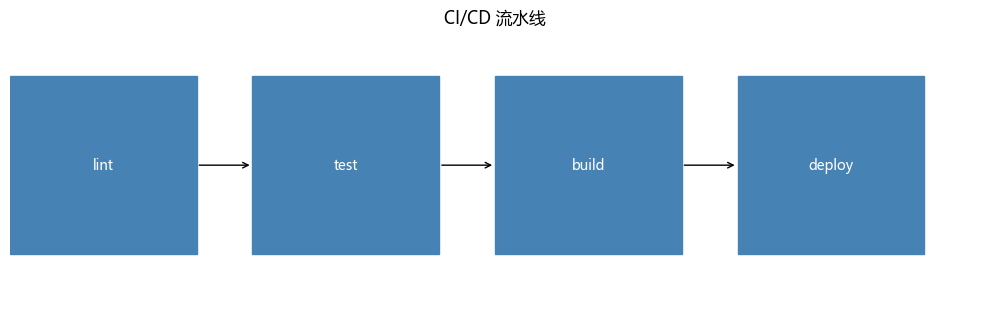

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 3.2))
stages = ['lint', 'test', 'build', 'deploy']
for i, s in enumerate(stages):
    ax.add_patch(plt.Rectangle((i*1.3, 0), 1.0, 0.8, color='steelblue'))
    ax.text(i*1.3+0.5, 0.4, s, ha='center', va='center', color='white')
    if i < 3: ax.annotate('', xy=(i*1.3+1.3, 0.4), xytext=(i*1.3+1.0, 0.4),
                          arrowprops=dict(arrowstyle='->'))
ax.set_xlim(0, 5.2); ax.set_ylim(-0.2, 1); ax.axis('off')
ax.set_title('CI/CD 流水线')
plt.tight_layout(); plt.show()

## 四、面试要点

- **容器化解决什么？** 环境一致性、依赖隔离、可快速复制与回滚，避免「在我机器上能跑」。
- **CI/CD 各阶段作用？** lint 静态检查、test 自动测试、build 构建镜像、deploy 受控发布，任一阶段失败即阻断。
- **镜像如何瘦身？** 用 slim 基础镜像、多阶段构建、合并层、清理缓存。
- **回滚如何实现？** 保留历史镜像版本，发布异常时快速切回上一版本。

## 五、练习

1. 写一个多阶段构建的 Dockerfile。
2. 给流水线加测试覆盖率门禁。
3. 实现配置与密钥分离（不打进镜像）。
4. 设计蓝绿部署的 compose 编排。